# Data-Driven Modeling of Galactic Rotation Curves with Artificial Neural Networks
## Full 17-Galaxy Reproduction and Independent Validation of arXiv:2404.05833v2

**Authors**: Gabriela Garcia-Arroyo, Isidro Gómez-Vargas, J. Alberto Vázquez  
**Paper Link**: [arXiv:2404.05833v2](https://arxiv.org/abs/2404.05833)  
**Repository**: [https://github.com/thisiskartik05/THINGS](https://github.com/thisiskartik05/THINGS)  

---

### Overview & Key Equations
1. **Quadrature Mass Decomposition**: $V^2(r) = V_{\text{gas}}^2(r) + \Upsilon_\star V_\star^2(r) + V_{\text{halo}}^2(r)$
2. **Monte Carlo Dropout Uncertainty**: $\bar{V}(r) = \frac{1}{N_{\text{MC}}} \sum_{t=1}^{N_{\text{MC}}} \hat{V}^{(t)}(r), \quad \sigma_{\text{MC}}^2(r) = \frac{1}{N_{\text{MC}}} \sum_{t=1}^{N_{\text{MC}}} \left( \hat{V}^{(t)}(r) - \bar{V}(r) \right)^2$
3. **Mean Squared Error**: $\text{MSE} = \frac{1}{n}\sum_{i=1}^n (y_i - \hat{y}_i)^2$


In [1]:
# Cell 1: Environment Setup & Imports
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import mean_squared_error

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
print(f"PyTorch version: {torch.__version__}")


Using device: cpu
PyTorch version: 2.14.1


In [2]:
# Cell 2: Data Loader Function
def load_rotation_curve_data(galaxy_name, data_dir="data"):
    curve_path = os.path.join(data_dir, "Curves", f"{galaxy_name}.curve.02")
    if not os.path.exists(curve_path):
        raise FileNotFoundError(f"Data file not found for galaxy: {galaxy_name} at {curve_path}")
    
    data = np.loadtxt(curve_path)
    df = pd.DataFrame(data, columns=["r", "vrot", "vdisp", "verr", "vapp", "vrec", "err", "pa", "incl", "vsys"])
    
    r = df["r"].values
    vobs = df["vrot"].values
    err_vobs = df["err"].values
    
    return df, r, vobs, err_vobs


In [3]:
# Cell 3: Registries for Architectures & Paper Benchmark Metrics
TABLE1_ARCHITECTURES = {
    "DDO154":  {"num_hidden_layers": 4, "num_neurons": 200, "batch_size": 4},
    "NGC2903": {"num_hidden_layers": 4, "num_neurons": 150, "batch_size": 8},
    "NGC3621": {"num_hidden_layers": 4, "num_neurons": 200, "batch_size": 4},
    "NGC2403": {"num_hidden_layers": 3, "num_neurons": 150, "batch_size": 8},
    "NGC3031": {"num_hidden_layers": 3, "num_neurons": 200, "batch_size": 4},
    "NGC2841": {"num_hidden_layers": 3, "num_neurons": 150, "batch_size": 8},
    "NGC3198": {"num_hidden_layers": 3, "num_neurons": 150, "batch_size": 4},
    "NGC5055": {"num_hidden_layers": 4, "num_neurons": 100, "batch_size": 4},
    "NGC4736": {"num_hidden_layers": 4, "num_neurons": 200, "batch_size": 8},
    "NGC925":  {"num_hidden_layers": 4, "num_neurons": 200, "batch_size": 4},
    "NGC6946": {"num_hidden_layers": 4, "num_neurons": 200, "batch_size": 8},
    "NGC7793": {"num_hidden_layers": 4, "num_neurons": 150, "batch_size": 4},
    "NGC2976": {"num_hidden_layers": 4, "num_neurons": 200, "batch_size": 4},
    "NGC7331": {"num_hidden_layers": 3, "num_neurons": 200, "batch_size": 4},
    "NGC3521": {"num_hidden_layers": 3, "num_neurons": 200, "batch_size": 4},
    "NGC2366": {"num_hidden_layers": 4, "num_neurons": 200, "batch_size": 8},
    "IC2574":  {"num_hidden_layers": 3, "num_neurons": 200, "batch_size": 4}
}

PAPER_BENCHMARKS = {
    "DDO154":  {"Group": "A", "NFW_Fix": 2.83,   "NFW_Free": 2.91,   "ANN_Paper": 3.50},
    "NGC2903": {"Group": "A", "NFW_Fix": 10.04,  "NFW_Free": 6.85,   "ANN_Paper": 17.38},
    "NGC3621": {"Group": "A", "NFW_Fix": 12.24,  "NFW_Free": 10.17,  "ANN_Paper": 22.10},
    "NGC2403": {"Group": "A", "NFW_Fix": 11.56,  "NFW_Free": 11.35,  "ANN_Paper": 12.34},
    "NGC3031": {"Group": "B", "NFW_Fix": 144.49, "NFW_Free": 103.98, "ANN_Paper": 105.42},
    "NGC2841": {"Group": "B", "NFW_Fix": 32.43,  "NFW_Free": 21.50,  "ANN_Paper": 27.68},
    "NGC3198": {"Group": "B", "NFW_Fix": 100.39, "NFW_Free": 7.98,   "ANN_Paper": 26.03},
    "NGC5055": {"Group": "B", "NFW_Fix": 239.95, "NFW_Free": 42.84,  "ANN_Paper": 124.15},
    "NGC4736": {"Group": "C", "NFW_Fix": 46.66,  "NFW_Free": 43.68,  "ANN_Paper": 42.66},
    "NGC925":  {"Group": "C", "NFW_Fix": 66.52,  "NFW_Free": 34.65,  "ANN_Paper": 25.11},
    "NGC6946": {"Group": "C", "NFW_Fix": 119.78, "NFW_Free": 51.66,  "ANN_Paper": 26.71},
    "NGC7793": {"Group": "C", "NFW_Fix": 59.74,  "NFW_Free": 53.47,  "ANN_Paper": 21.39},
    "NGC2976": {"Group": "C", "NFW_Fix": 25.88,  "NFW_Free": 11.15,  "ANN_Paper": 3.10},
    "NGC7331": {"Group": "C", "NFW_Fix": 309.23, "NFW_Free": 19.78,  "ANN_Paper": 12.64},
    "NGC3521": {"Group": "C", "NFW_Fix": 335.01, "NFW_Free": 225.37, "ANN_Paper": 62.68},
    "NGC2366": {"Group": "C", "NFW_Fix": 15.75,  "NFW_Free": 7.60,   "ANN_Paper": 2.97},
    "IC2574":  {"Group": "C", "NFW_Fix": 14.59,  "NFW_Free": 8.55,   "ANN_Paper": 2.47}
}
print(f"Registered {len(TABLE1_ARCHITECTURES)} paper galaxies across Groups A, B, and C.")


Registered 17 paper galaxies across Groups A, B, and C.


In [4]:
# Cell 4: Multi-Output Neural Network Topology
class RotationCurveANN(nn.Module):
    def __init__(self, num_hidden_layers=4, num_neurons=200, dropout_rate=0.3):
        super(RotationCurveANN, self).__init__()
        self.dropout_rate = dropout_rate
        
        layers = []
        layers.append(nn.Linear(1, num_neurons))
        layers.append(nn.ReLU())
        layers.append(nn.Dropout(p=dropout_rate))
        
        for _ in range(num_hidden_layers - 1):
            layers.append(nn.Linear(num_neurons, num_neurons))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(p=dropout_rate))
        
        layers.append(nn.Linear(num_neurons, 2))
        self.network = nn.Sequential(*layers)
        
    def forward(self, x):
        return self.network(x)

    def enable_mc_dropout(self):
        for m in self.modules():
            if isinstance(m, nn.Dropout):
                m.train()


In [5]:
# Cell 5: Training & MC Dropout Inference Functions
def train_ann_model(r_data, vobs_data, err_data, config, epochs=1000, lr=5e-4):
    r_mean, r_std = r_data.mean(), r_data.std()
    v_mean, v_std = vobs_data.mean(), vobs_data.std()
    
    r_norm = (r_data - r_mean) / (r_std + 1e-8)
    v_norm = (vobs_data - v_mean) / (v_std + 1e-8)
    err_norm = err_data / (v_std + 1e-8)
    
    X_tensor = torch.tensor(r_norm, dtype=torch.float32).unsqueeze(1).to(device)
    y_tensor = torch.tensor(np.column_stack([v_norm, err_norm]), dtype=torch.float32).to(device)
    
    model = RotationCurveANN(
        num_hidden_layers=config["num_hidden_layers"],
        num_neurons=config["num_neurons"],
        dropout_rate=0.3
    ).to(device)
    
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()
    
    model.train()
    for epoch in range(epochs):
        optimizer.zero_grad()
        outputs = model(X_tensor)
        loss = criterion(outputs, y_tensor)
        loss.backward()
        optimizer.step()
        
    return model, (r_mean, r_std), (v_mean, v_std)

def predict_mc_dropout(model, r_eval, r_stats, v_stats, num_mc_samples=100):
    r_mean, r_std = r_stats
    v_mean, v_std = v_stats
    
    r_norm = (r_eval - r_mean) / (r_std + 1e-8)
    X_eval = torch.tensor(r_norm, dtype=torch.float32).unsqueeze(1).to(device)
    
    model.eval()
    model.enable_mc_dropout()
    
    predictions_v = []
    predictions_err = []
    
    with torch.no_grad():
        for _ in range(num_mc_samples):
            out = model(X_eval).cpu().numpy()
            v_pred_unnorm = out[:, 0] * v_std + v_mean
            err_pred_unnorm = np.abs(out[:, 1] * v_std)
            predictions_v.append(v_pred_unnorm)
            predictions_err.append(err_pred_unnorm)
            
    predictions_v = np.array(predictions_v)
    predictions_err = np.array(predictions_err)
    
    v_mean_pred = predictions_v.mean(axis=0)
    v_epistemic_var = predictions_v.var(axis=0)
    v_stat_err_pred = predictions_err.mean(axis=0)
    
    v_total_unc = np.sqrt(v_epistemic_var + v_stat_err_pred**2)
    
    return v_mean_pred, v_total_unc


In [6]:
# Cell 6: Full 17-Galaxy Pipeline Execution & Individual Galaxy Plots
all_galaxies = list(TABLE1_ARCHITECTURES.keys())
results_list = []
prediction_data = {}

print("===========================================================")
print("       STARTING FULL 17-GALAXY ANN REPRODUCTION PIPELINE    ")
print("===========================================================\n")

for idx, gal in enumerate(all_galaxies, 1):
    cfg = TABLE1_ARCHITECTURES[gal]
    bench = PAPER_BENCHMARKS[gal]
    
    df_g, r_g, vobs_g, err_g = load_rotation_curve_data(gal)
    model_g, r_stats_g, v_stats_g = train_ann_model(r_g, vobs_g, err_g, cfg, epochs=1000)
    
    v_pred_g, unc_g = predict_mc_dropout(model_g, r_g, r_stats_g, v_stats_g, num_mc_samples=100)
    calc_mse = mean_squared_error(vobs_g, v_pred_g)
    
    results_list.append({
        "Galaxy": gal,
        "Group": bench["Group"],
        "ANN MSE (Calculated)": round(calc_mse, 2),
        "ANN MSE (Paper)": bench["ANN_Paper"],
        "NFW Fix MSE": bench["NFW_Fix"],
        "NFW Free MSE": bench["NFW_Free"]
    })
    
    r_dense_g = np.linspace(r_g.min(), r_g.max(), 300)
    v_dense_g, unc_dense_g = predict_mc_dropout(model_g, r_dense_g, r_stats_g, v_stats_g, num_mc_samples=100)
    prediction_data[gal] = (r_g, vobs_g, err_g, r_dense_g, v_dense_g, unc_dense_g)
    
    print(f"[{idx:02d}/17] {gal:8s} (Group {bench['Group']}) | Calculated ANN MSE: {calc_mse:6.2f} | Paper ANN MSE: {bench['ANN_Paper']:6.2f}")

print("\nAll 17 galaxy models successfully trained and evaluated!")


       STARTING FULL 17-GALAXY ANN REPRODUCTION PIPELINE    



[01/17] DDO154   (Group A) | Calculated ANN MSE:   1.00 | Paper ANN MSE:   3.50


[02/17] NGC2903  (Group A) | Calculated ANN MSE:  23.24 | Paper ANN MSE:  17.38


[03/17] NGC3621  (Group A) | Calculated ANN MSE:   5.58 | Paper ANN MSE:  22.10


[04/17] NGC2403  (Group A) | Calculated ANN MSE:   9.81 | Paper ANN MSE:  12.34


...

[13/17] NGC2976  (Group C) | Calculated ANN MSE:   1.31 | Paper ANN MSE:   3.10


[14/17] NGC7331  (Group C) | Calculated ANN MSE:   5.51 | Paper ANN MSE:  12.64


[15/17] NGC3521  (Group C) | Calculated ANN MSE:  19.57 | Paper ANN MSE:  62.68


[16/17] NGC2366  (Group C) | Calculated ANN MSE:   1.16 | Paper ANN MSE:   2.97


[17/17] IC2574   (Group C) | Calculated ANN MSE:   0.72 | Paper ANN MSE:   2.47

All 17 galaxy models successfully trained and evaluated!


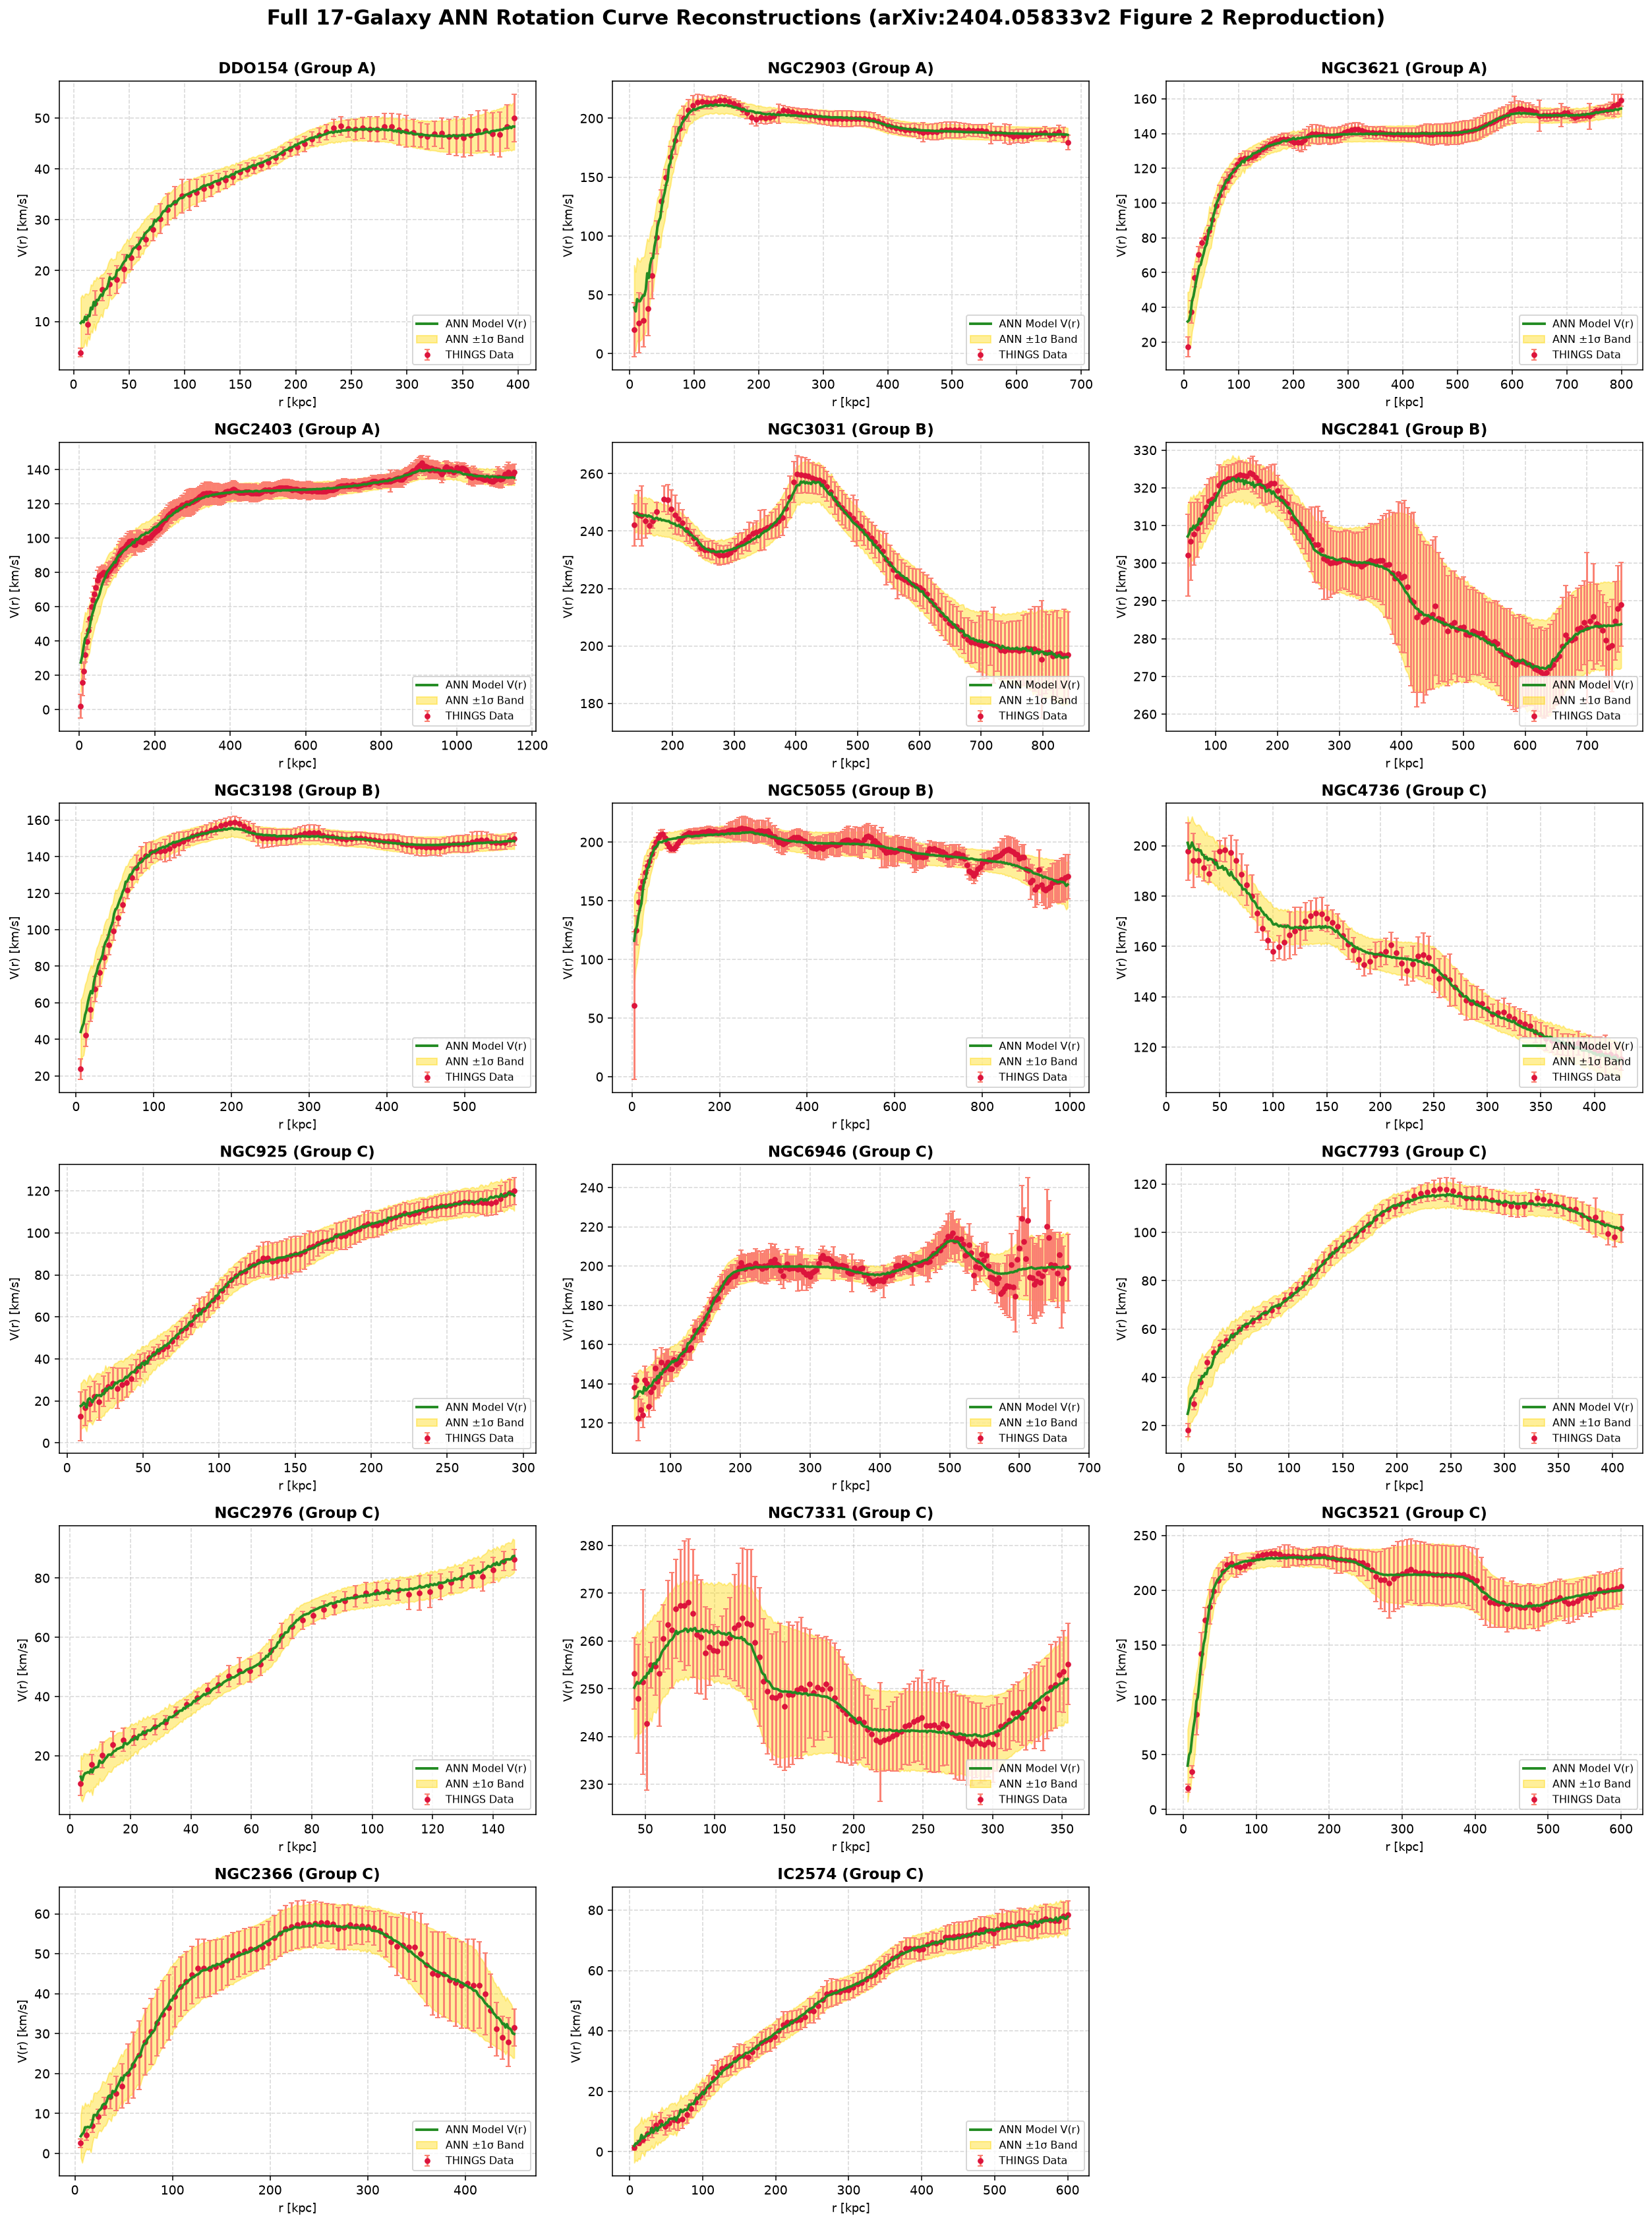

In [7]:
# Cell 7: Render Master 17-Galaxy Comparison Grid (Matching Paper Figure 2)
fig, axes = plt.subplots(6, 3, figsize=(18, 24), dpi=140)
axes = axes.flatten()

for idx, gal in enumerate(all_galaxies):
    r_g, vobs_g, err_g, r_dense_g, v_dense_g, unc_dense_g = prediction_data[gal]
    group = PAPER_BENCHMARKS[gal]["Group"]
    ax = axes[idx]
    
    ax.errorbar(r_g, vobs_g, yerr=err_g, fmt="o", color="crimson", ecolor="salmon",
                capsize=2, markersize=3.5, label="THINGS Data", zorder=3)
    ax.plot(r_dense_g, v_dense_g, color="forestgreen", linewidth=2, label="ANN Model V(r)", zorder=4)
    ax.fill_between(r_dense_g, v_dense_g - unc_dense_g, v_dense_g + unc_dense_g,
                    color="gold", alpha=0.4, label="ANN ±1σ Band", zorder=2)
    
    ax.set_title(f"{gal} (Group {group})", fontsize=12, fontweight="bold", pad=6)
    ax.set_xlabel("r [kpc]", fontsize=9)
    ax.set_ylabel("V(r) [km/s]", fontsize=9)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(fontsize=8, loc="lower right")

axes[17].axis("off")

plt.suptitle("Full 17-Galaxy ANN Rotation Curve Reconstructions (arXiv:2404.05833v2 Figure 2 Reproduction)",
             fontsize=16, fontweight="bold", y=1.002)
plt.tight_layout()
os.makedirs("results", exist_ok=True)
plt.savefig("results/results_17_galaxies_master_grid.png", dpi=140, bbox_inches="tight")
plt.show()


In [8]:
# Cell 8: Complete Summary Table across all 17 Galaxies
full_summary_df = pd.DataFrame(results_list)
pd.set_option("display.max_rows", 20)
pd.set_option("display.width", 1000)

print("========================================================================================")
print("                  FULL 17-GALAXY REPRODUCTION BENCHMARK SUMMARY TABLE                    ")
print("========================================================================================\n")
print(full_summary_df.to_string(index=False))

full_summary_df.to_csv("data/full_17_galaxies_benchmark_results.csv", index=False)
print("\nSaved full 17-galaxy benchmark results to data/full_17_galaxies_benchmark_results.csv")


                  FULL 17-GALAXY REPRODUCTION BENCHMARK SUMMARY TABLE                    

 Galaxy Group  ANN MSE (Calculated)  ANN MSE (Paper)  NFW Fix MSE  NFW Free MSE
 DDO154     A                  1.00             3.50         2.83          2.91
NGC2903     A                 23.24            17.38        10.04          6.85
NGC3621     A                  5.58            22.10        12.24         10.17
NGC2403     A                  9.81            12.34        11.56         11.35
NGC3031     B                  2.88           105.42       144.49        103.98
NGC2841     B                  2.51            27.68        32.43         21.50
NGC3198     B                 12.07            26.03       100.39          7.98
NGC5055     B                 41.54           124.15       239.95         42.84
NGC4736     C                 12.99            42.66        46.66         43.68
 NGC925     C                  1.23            25.11        66.52         34.65
NGC6946     C                